Filtered Training Samples: 12000
Filtered Testing Samples: 2000


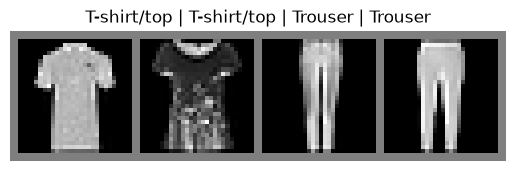

In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

# 1. Define image transformations
# We convert images to PyTorch tensors and normalize pixel values to [-1, 1]
# Normalization is crucial for quantum embedding (specifically Angle Encoding) later.
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)) 
])

# 2. Download and load the Fashion-MNIST dataset
train_dataset = torchvision.datasets.FashionMNIST(
    root='../data', 
    train=True, 
    download=True, 
    transform=transform
)

test_dataset = torchvision.datasets.FashionMNIST(
    root='../data', 
    train=False, 
    download=True, 
    transform=transform
)

# 3. Filter for Binary Classification (Classes 0: T-shirt/top, and 1: Trouser)
def filter_binary_classes(dataset, class1=0, class2=1):
    """Filters a PyTorch dataset to keep only two specific classes."""
    # Find indices where the label is either class1 or class2
    idx = (dataset.targets == class1) | (dataset.targets == class2)
    dataset.targets = dataset.targets[idx]
    dataset.data = dataset.data[idx]
    
    # Remap labels to 0 and 1 for binary cross-entropy loss later
    dataset.targets[dataset.targets == class1] = 0
    dataset.targets[dataset.targets == class2] = 1
    return dataset

train_dataset_binary = filter_binary_classes(train_dataset, 0, 1)
test_dataset_binary = filter_binary_classes(test_dataset, 0, 1)

print(f"Filtered Training Samples: {len(train_dataset_binary)}")
print(f"Filtered Testing Samples: {len(test_dataset_binary)}")

# 4. Visualize the data
def imshow(img, title):
    """Helper function to un-normalize and display an image."""
    img = img / 2 + 0.5  # Un-normalize back to [0, 1]
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)), cmap='gray')
    plt.title(title)
    plt.axis('off')
    plt.show()

# Get a batch of random training images
train_loader = torch.utils.data.DataLoader(train_dataset_binary, batch_size=4, shuffle=True)
dataiter = iter(train_loader)
images, labels = next(dataiter)

# Show images
class_names = ['T-shirt/top', 'Trouser']
title = ' | '.join(f'{class_names[labels[j]]}' for j in range(4))
imshow(torchvision.utils.make_grid(images), title)

In [2]:
from sklearn.decomposition import PCA

print("Flattening and applying PCA...")

# 1. Flatten the 28x28 images to 1D arrays of length 784
X_train = train_dataset_binary.data.view(-1, 784).numpy() 
y_train = train_dataset_binary.targets.numpy()

X_test = test_dataset_binary.data.view(-1, 784).numpy()
y_test = test_dataset_binary.targets.numpy()

# 2. Initialize PCA to reduce 784 features down to just 4 features
n_features = 4
pca = PCA(n_components=n_features)

# Fit PCA on the training data and transform both train and test sets
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# 3. Feature Scaling for Quantum Encoding
# Quantum rotation gates (like RX, RY, RZ) expect angles. 
# We must scale our PCA outputs to be between 0 and pi (π) radians.
def normalize_to_angles(data):
    min_val = np.min(data, axis=0)
    max_val = np.max(data, axis=0)
    # Scales data to [0, 1] then multiplies by π
    return (data - min_val) / (max_val - min_val) * np.pi 

X_train_angles = normalize_to_angles(X_train_pca)
X_test_angles = normalize_to_angles(X_test_pca)

# 4. Convert back to PyTorch Tensors for our Neural Network
X_train_tensor = torch.tensor(X_train_angles, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
X_test_tensor = torch.tensor(X_test_angles, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

print(f"Classical Data successfully reduced from 784 to {n_features} features!")
print(f"Shape of X_train_tensor: {X_train_tensor.shape}")

Flattening and applying PCA...
Classical Data successfully reduced from 784 to 4 features!
Shape of X_train_tensor: torch.Size([12000, 4])


In [3]:
import pennylane as qml
import torch.nn as nn

# --- 1. Define the Quantum Circuit (QNode) ---
n_qubits = n_features # 4 qubits to match our 4 PCA features
dev = qml.device("default.qubit", wires=n_qubits)

# Depth is the number of trainable quantum layers. 
# 2 is perfect for proving the concept on a laptop without taking hours to train.
q_depth = 2 

@qml.qnode(dev, interface="torch")
def qnode(inputs, weights):
    # Step A: Data Encoding (Classical -> Quantum)
    qml.AngleEmbedding(inputs, wires=range(n_qubits))
    
    # Step B: Trainable Quantum Layers
    # This applies a sequence of rotations and CNOT gates based on 'weights'
    qml.StronglyEntanglingLayers(weights, wires=range(n_qubits))
    
    # Step C: Measurement (Quantum -> Classical)
    # We measure the expectation value of each qubit along the Z-axis
    return [qml.expval(qml.PauliZ(wires=i)) for i in range(n_qubits)]


# --- 2. Wrap it into a PyTorch Hybrid Model ---
# We must tell PyTorch the shape of the weights the quantum circuit expects
weight_shapes = {"weights": (q_depth, n_qubits, 3)}

class HybridQNN(nn.Module):
    def __init__(self):
        super(HybridQNN, self).__init__()
        
        # 1. The Quantum Layer (PennyLane handles the complex math behind the scenes)
        self.qlayer = qml.qnn.TorchLayer(qnode, weight_shapes)
        
        # 2. The Classical Output Layer
        # Maps the 4 output values from the qubits to 2 probabilities (T-shirt vs Trouser)
        self.clayer = nn.Linear(n_qubits, 2)
        
    def forward(self, x):
        # Forward pass: Data goes through Quantum, then Classical
        x = self.qlayer(x)
        x = self.clayer(x)
        return x

# Initialize the model
model = HybridQNN()
print("Hybrid Quantum-Classical Model successfully initialized!")

Hybrid Quantum-Classical Model successfully initialized!


In [4]:
from torch.utils.data import TensorDataset, DataLoader

# --- 1. Define Hyperparameters ---
# Since quantum simulators are computationally heavy, we will use a small batch size 
# and a few epochs just to prove the model learns.
batch_size = 16
epochs = 5
learning_rate = 0.01

# --- 2. Create PyTorch DataLoaders ---
# Combine the features and labels into standard PyTorch TensorDatasets
train_dataset_final = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset_final = TensorDataset(X_test_tensor, y_test_tensor)

# DataLoaders handle shuffling and batching the data automatically
train_loader = DataLoader(train_dataset_final, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset_final, batch_size=batch_size, shuffle=False)

print(f"DataLoaders ready! Training batches: {len(train_loader)}")

DataLoaders ready! Training batches: 750


In [5]:
import torch.optim as optim

# --- 1. Define Loss and Optimizer ---
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# Lists to keep track of our progress for plotting later
train_losses = []
train_accuracies = []

print("Starting Quantum Model Training...")

# --- 2. The Training Loop ---
for epoch in range(epochs):
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0
    
    # Iterate through the data in batches
    for batch_features, batch_labels in train_loader:
        
        # Step A: Zero the gradients (clear old calculations)
        optimizer.zero_grad()
        
        # Step B: Forward Pass (Push data through the quantum circuit)
        outputs = model(batch_features)
        
        # Step C: Calculate the Loss (How wrong the model was)
        loss = criterion(outputs, batch_labels)
        
        # Step D: Backward Pass (Calculate gradients using PennyLane's automatic differentiation)
        loss.backward()
        
        # Step E: Optimize (Update the classical weights and quantum rotation angles)
        optimizer.step()
        
        # Track metrics
        running_loss += loss.item()
        
        # Calculate accuracy for this batch
        _, predicted = torch.max(outputs.data, 1)
        total_samples += batch_labels.size(0)
        correct_predictions += (predicted == batch_labels).sum().item()
        
    # Epoch summaries
    epoch_loss = running_loss / len(train_loader)
    epoch_acc = (correct_predictions / total_samples) * 100
    
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_acc)
    
    print(f"Epoch [{epoch+1}/{epochs}] | Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc:.2f}%")

print("Training Complete!")

Starting Quantum Model Training...
Epoch [1/5] | Loss: 0.1457 | Accuracy: 95.37%
Epoch [2/5] | Loss: 0.0710 | Accuracy: 97.57%
Epoch [3/5] | Loss: 0.0649 | Accuracy: 97.72%
Epoch [4/5] | Loss: 0.0641 | Accuracy: 97.67%
Epoch [5/5] | Loss: 0.0641 | Accuracy: 97.70%
Training Complete!


Evaluating model on test dataset...

--- Classification Report ---
              precision    recall  f1-score   support

 T-shirt/top       0.99      0.82      0.90      1000
     Trouser       0.85      0.99      0.91      1000

    accuracy                           0.91      2000
   macro avg       0.92      0.91      0.90      2000
weighted avg       0.92      0.91      0.90      2000



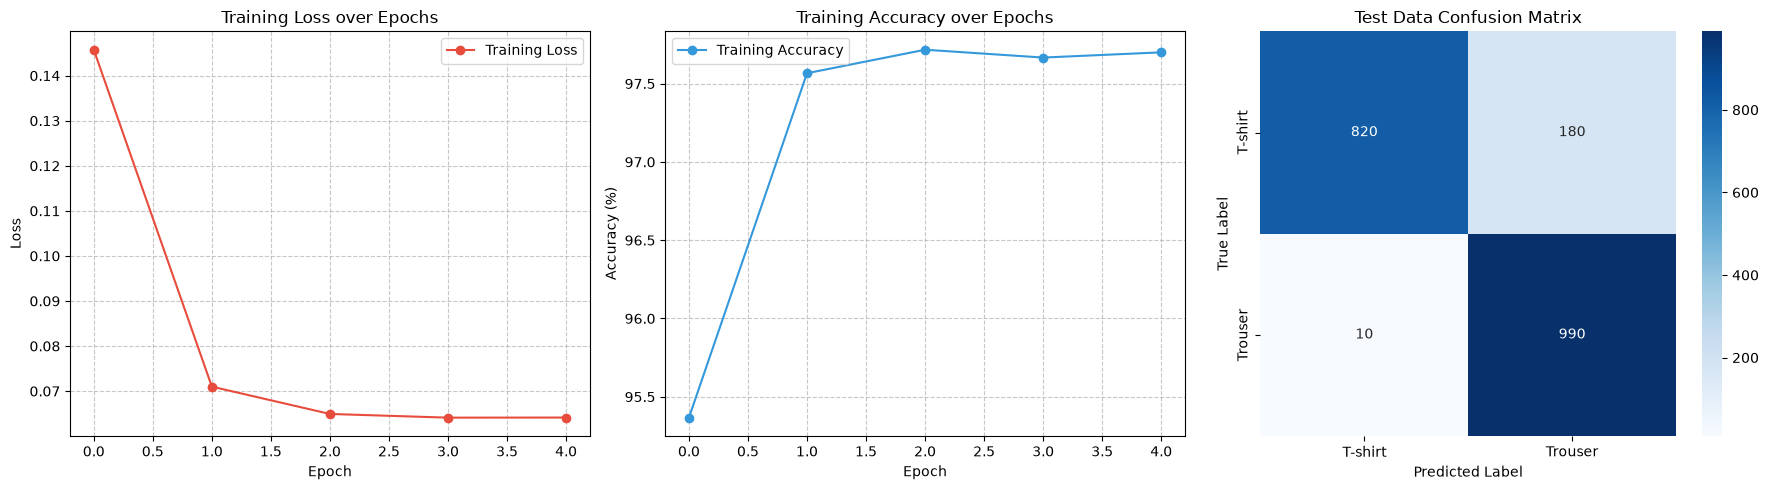

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import torch

# --- 1. Evaluate on Test Data ---
print("Evaluating model on test dataset...")
model.eval() # Set model to evaluation mode so weights do not change

all_preds = []
all_labels = []

with torch.no_grad(): # Turn off gradient tracking for faster testing
    for batch_features, batch_labels in test_loader:
        outputs = model(batch_features)
        
        # Get the highest probability class
        _, predicted = torch.max(outputs, 1)
        
        # Store predictions and true labels for metric calculations
        all_preds.extend(predicted.numpy())
        all_labels.extend(batch_labels.numpy())

# --- 2. Print Classification Report ---
# This automatically calculates Precision, Recall, and F1-Score
print("\n--- Classification Report ---")
print(classification_report(all_labels, all_preds, target_names=['T-shirt/top', 'Trouser']))

# --- 3. Generate Professional Visualizations ---
# We will create a 1x3 grid of charts for your project report
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chart A: Training Loss
axes[0].plot(train_losses, label='Training Loss', color='#e74c3c', marker='o')
axes[0].set_title('Training Loss over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].grid(True, linestyle='--', alpha=0.7)
axes[0].legend()

# Chart B: Training Accuracy
axes[1].plot(train_accuracies, label='Training Accuracy', color='#3498db', marker='o')
axes[1].set_title('Training Accuracy over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].grid(True, linestyle='--', alpha=0.7)
axes[1].legend()

# Chart C: Confusion Matrix Heatmap
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2], 
            xticklabels=['T-shirt', 'Trouser'], yticklabels=['T-shirt', 'Trouser'])
axes[2].set_title('Test Data Confusion Matrix')
axes[2].set_xlabel('Predicted Label')
axes[2].set_ylabel('True Label')

plt.tight_layout()
plt.show()

In [7]:
import time
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

# --- 1. Define the Classical CNN ---
# We will use a lightweight CNN for a fair comparison against our small QNN
class ClassicalCNN(nn.Module):
    def __init__(self):
        super(ClassicalCNN, self).__init__()
        # 1 input channel (grayscale), 4 output channels (filters), 3x3 kernel
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=4, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        # After pooling, the 28x28 image becomes 14x14. 
        # Flattened size: 4 channels * 14 * 14 = 784 classical features
        self.fc = nn.Linear(784, 2)

    def forward(self, x):
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)
        x = x.view(x.size(0), -1) # Flatten for the linear layer
        x = self.fc(x)
        return x

cnn_model = ClassicalCNN()

# --- 2. Prepare DataLoaders for Original Images ---
# The CNN needs the original 2D images, not the 1D PCA features we used for the QNN
cnn_train_loader = DataLoader(train_dataset_binary, batch_size=16, shuffle=True)
cnn_test_loader = DataLoader(test_dataset_binary, batch_size=16, shuffle=False)

# --- 3. Train the Classical CNN ---
cnn_optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)
cnn_criterion = nn.CrossEntropyLoss()

print("Starting Classical CNN Training...")
start_time = time.time()

cnn_epochs = 5
for epoch in range(cnn_epochs):
    running_loss = 0.0
    for images, labels in cnn_train_loader:
        cnn_optimizer.zero_grad()
        
        # Forward pass
        outputs = cnn_model(images)
        loss = cnn_criterion(outputs, labels)
        
        # Backward pass and optimize
        loss.backward()
        cnn_optimizer.step()
        
        running_loss += loss.item()
        
    epoch_loss = running_loss / len(cnn_train_loader)
    print(f"Epoch [{epoch+1}/{cnn_epochs}] | Loss: {epoch_loss:.4f}")

cnn_time = time.time() - start_time
print(f"Classical CNN Training Complete in {cnn_time:.2f} seconds!")

Starting Classical CNN Training...
Epoch [1/5] | Loss: 0.0656
Epoch [2/5] | Loss: 0.0286
Epoch [3/5] | Loss: 0.0244
Epoch [4/5] | Loss: 0.0232
Epoch [5/5] | Loss: 0.0200
Classical CNN Training Complete in 11.60 seconds!


In [8]:
# --- 1. Compare Model Complexity (Parameter Count) ---
qnn_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
cnn_params = sum(p.numel() for p in cnn_model.parameters() if p.requires_grad)

print("--- Model Complexity Comparison ---")
print(f"Hybrid QNN Trainable Parameters: {qnn_params}")
print(f"Classical CNN Trainable Parameters: {cnn_params}")

--- Model Complexity Comparison ---
Hybrid QNN Trainable Parameters: 34
Classical CNN Trainable Parameters: 1610


In [9]:
# --- Evaluate Classical CNN on Test Data ---
print("Evaluating Classical CNN on test dataset...")
cnn_model.eval() # Set model to evaluation mode

cnn_correct = 0
cnn_total = 0
cnn_all_preds = []
cnn_all_labels = []

with torch.no_grad():
    for images, labels in cnn_test_loader:
        outputs = cnn_model(images)
        _, predicted = torch.max(outputs.data, 1)
        
        cnn_total += labels.size(0)
        cnn_correct += (predicted == labels).sum().item()
        
        cnn_all_preds.extend(predicted.numpy())
        cnn_all_labels.extend(labels.numpy())

cnn_accuracy = (cnn_correct / cnn_total) * 100
print(f"\nClassical CNN Test Accuracy: {cnn_accuracy:.2f}%")

print("\n--- Classical CNN Classification Report ---")
print(classification_report(cnn_all_labels, cnn_all_preds, target_names=['T-shirt/top', 'Trouser']))

Evaluating Classical CNN on test dataset...

Classical CNN Test Accuracy: 99.15%

--- Classical CNN Classification Report ---
              precision    recall  f1-score   support

 T-shirt/top       0.99      0.99      0.99      1000
     Trouser       0.99      0.99      0.99      1000

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000



In [10]:
# --- Part 2: Benchmarking on CIFAR-100 (Color Images) ---
import torchvision
import torchvision.transforms as transforms
import numpy as np

# 1. Download CIFAR-100 dataset (matching your normalization strategy)
cifar_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)) 
])

cifar_train_raw = torchvision.datasets.CIFAR100(root='../data', train=True, download=True, transform=cifar_transform)
cifar_test_raw = torchvision.datasets.CIFAR100(root='../data', train=False, download=True, transform=cifar_transform)

# 2. Filter for Binary Classification (Class 0: apple vs Class 1: aquarium_fish)
def filter_cifar_binary(dataset, class1=0, class2=1):
    targets_np = np.array(dataset.targets)
    idx = (targets_np == class1) | (targets_np == class2)
    dataset.targets = targets_np[idx].tolist()
    dataset.data = dataset.data[idx]
    
    # Remap to 0 and 1 for CrossEntropyLoss
    dataset.targets = [0 if label == class1 else 1 for label in dataset.targets]
    return dataset

cifar_train_binary = filter_cifar_binary(cifar_train_raw, 0, 1)
cifar_test_binary = filter_cifar_binary(cifar_test_raw, 0, 1)
print(f"CIFAR-100 Binary Training Samples: {len(cifar_train_binary)}")

100.0%


CIFAR-100 Binary Training Samples: 1000


In [12]:
from sklearn.decomposition import PCA

print("Flattening and applying PCA for CIFAR-100...")

# 1. Flatten the 32x32x3 RGB images to 1D arrays of length 3072
X_train_cifar = cifar_train_binary.data.reshape(-1, 3072) / 255.0
y_train_cifar = np.array(cifar_train_binary.targets)

X_test_cifar = cifar_test_binary.data.reshape(-1, 3072) / 255.0
y_test_cifar = np.array(cifar_test_binary.targets)

# 2. Initialize PCA to reduce 3072 features down to 4 features
pca_cifar = PCA(n_components=4)
X_train_cifar_pca = pca_cifar.fit_transform(X_train_cifar)
X_test_cifar_pca = pca_cifar.transform(X_test_cifar)

# 3. Apply your existing angle normalization function
X_train_cifar_angles = normalize_to_angles(X_train_cifar_pca)
X_test_cifar_angles = normalize_to_angles(X_test_cifar_pca)

print("CIFAR-100 Data successfully reduced from 3072 to 4 features and normalized to angles!")

Flattening and applying PCA for CIFAR-100...
CIFAR-100 Data successfully reduced from 3072 to 4 features and normalized to angles!


In [13]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Convert back to PyTorch Tensors
X_train_cifar_tensor = torch.tensor(X_train_cifar_angles, dtype=torch.float32)
y_train_cifar_tensor = torch.tensor(y_train_cifar, dtype=torch.long)
X_test_cifar_tensor = torch.tensor(X_test_cifar_angles, dtype=torch.float32)
y_test_cifar_tensor = torch.tensor(y_test_cifar, dtype=torch.long)

# Create distinct DataLoaders using your original batch_size of 16
cifar_train_dataset = TensorDataset(X_train_cifar_tensor, y_train_cifar_tensor)
cifar_test_dataset = TensorDataset(X_test_cifar_tensor, y_test_cifar_tensor)

cifar_train_loader = DataLoader(cifar_train_dataset, batch_size=16, shuffle=True)
cifar_test_loader = DataLoader(cifar_test_dataset, batch_size=16, shuffle=False)

print(f"CIFAR DataLoaders ready! Training batches: {len(cifar_train_loader)}")

CIFAR DataLoaders ready! Training batches: 63


In [14]:
import torch.optim as optim
import torch.nn as nn

# Re-initialize the exact class you used for Fashion-MNIST to create a fresh model
cifar_model = HybridQNN()

cifar_criterion = nn.CrossEntropyLoss()
cifar_optimizer = optim.Adam(cifar_model.parameters(), lr=0.01)

print("Fresh Hybrid QNN initialized for CIFAR-100!")

Fresh Hybrid QNN initialized for CIFAR-100!


In [15]:
cifar_epochs = 5
cifar_train_losses = []
cifar_train_accuracies = []

print("Starting Quantum Model Training on CIFAR-100...")

for epoch in range(cifar_epochs):
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0
    
    for batch_features, batch_labels in cifar_train_loader:
        cifar_optimizer.zero_grad()
        
        outputs = cifar_model(batch_features)
        loss = cifar_criterion(outputs, batch_labels)
        
        loss.backward()
        cifar_optimizer.step()
        
        running_loss += loss.item()
        
        _, predicted = torch.max(outputs.data, 1)
        total_samples += batch_labels.size(0)
        correct_predictions += (predicted == batch_labels).sum().item()
        
    epoch_loss = running_loss / len(cifar_train_loader)
    epoch_acc = (correct_predictions / total_samples) * 100
    
    cifar_train_losses.append(epoch_loss)
    cifar_train_accuracies.append(epoch_acc)
    
    print(f"Epoch [{epoch+1}/{cifar_epochs}] | Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc:.2f}%")

print("CIFAR-100 Training Complete!")

Starting Quantum Model Training on CIFAR-100...
Epoch [1/5] | Loss: 0.6391 | Accuracy: 66.70%
Epoch [2/5] | Loss: 0.5089 | Accuracy: 75.80%
Epoch [3/5] | Loss: 0.4778 | Accuracy: 76.60%
Epoch [4/5] | Loss: 0.4527 | Accuracy: 77.30%
Epoch [5/5] | Loss: 0.4343 | Accuracy: 78.80%
CIFAR-100 Training Complete!


Evaluating CIFAR-100 model on test dataset...

--- CIFAR-100 Classification Report ---
               precision    recall  f1-score   support

        Apple       0.74      0.90      0.81       100
Aquarium Fish       0.87      0.69      0.77       100

     accuracy                           0.80       200
    macro avg       0.81      0.79      0.79       200
 weighted avg       0.81      0.80      0.79       200



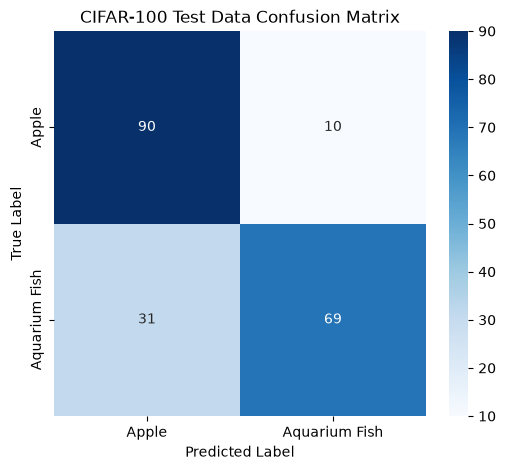

In [16]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

print("Evaluating CIFAR-100 model on test dataset...")
cifar_model.eval()

cifar_all_preds = []
cifar_all_labels = []

with torch.no_grad():
    for batch_features, batch_labels in cifar_test_loader:
        outputs = cifar_model(batch_features)
        _, predicted = torch.max(outputs, 1)
        
        cifar_all_preds.extend(predicted.numpy())
        cifar_all_labels.extend(batch_labels.numpy())

print("\n--- CIFAR-100 Classification Report ---")
print(classification_report(cifar_all_labels, cifar_all_preds, target_names=['Apple', 'Aquarium Fish']))

# Generate Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(cifar_all_labels, cifar_all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, 
            xticklabels=['Apple', 'Aquarium Fish'], yticklabels=['Apple', 'Aquarium Fish'])
ax.set_title('CIFAR-100 Test Data Confusion Matrix')
ax.set_xlabel('Predicted Label')
ax.set_ylabel('True Label')
plt.show()